<a href="https://colab.research.google.com/github/azrabozkale/tubitak-iha-nesne-tespiti/blob/main/tubitak-iha-nesne-tespiti.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Colab hücresine yazıp çalıştıracaksın:
!pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 20.5/107.7 GB disk)



image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 382.9ms
Speed: 30.8ms preprocess, 382.9ms inference, 35.4ms postprocess per image at shape (1, 3, 640, 480)


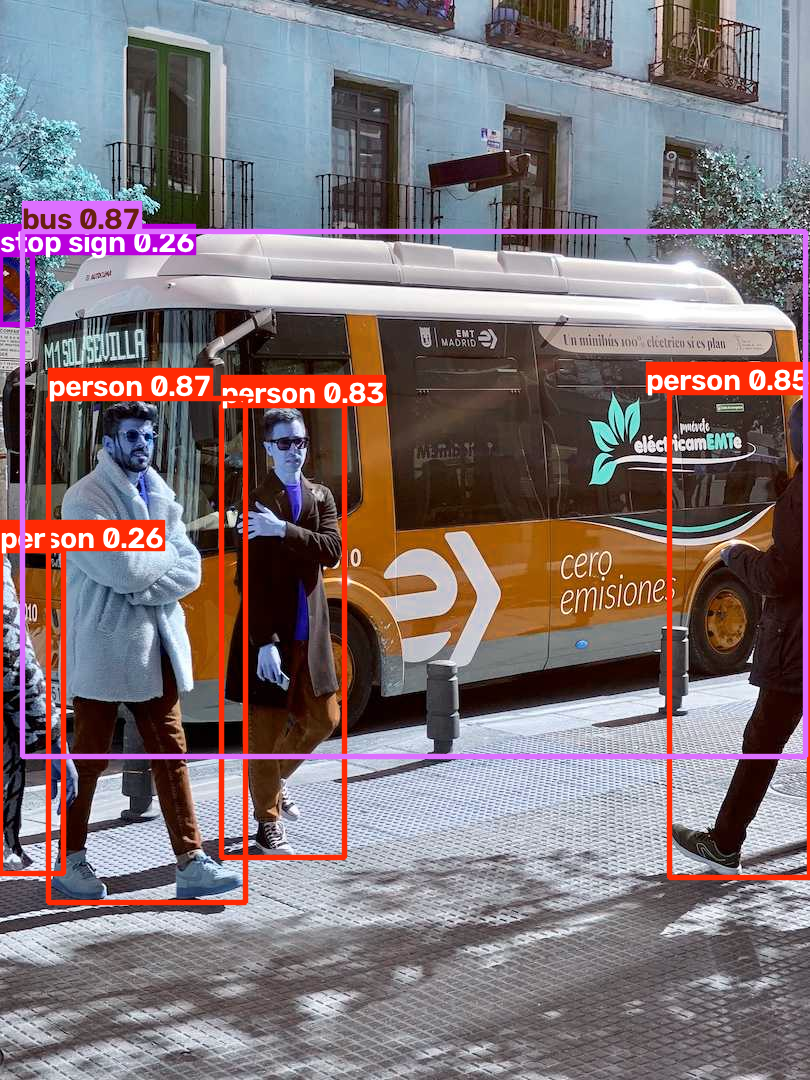

In [2]:
from ultralytics import YOLO

# YOLO'nun önceden eğitilmiş hafif bir modelini çağırıyoruz
model = YOLO("yolov8n.pt")

# İnternetten örnek bir fotoğraf üzerinde nesne tespiti yapalım (YOLO'nun kendi örnek görseli)
results = model("https://ultralytics.com/images/bus.jpg")

# Sonuçları ekranda göster
from PIL import Image; Image.fromarray(results[0].plot())

In [1]:
import torch
print("GPU Aktif mi?", torch.cuda.is_available())

GPU Aktif mi? True


In [2]:
import torch
print("GPU Aktif mi?:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Kullanılan Ekran Kartı:", torch.cuda.get_device_name(0))

GPU Aktif mi?: True
Kullanılan Ekran Kartı: Tesla T4


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 7.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/zidane.jpg: 384x640 2 persons, 1 tie, 9.1ms
Speed: 90.8ms preprocess, 9.1ms inference, 37.7ms postprocess per image at shape (1, 3, 384, 640)


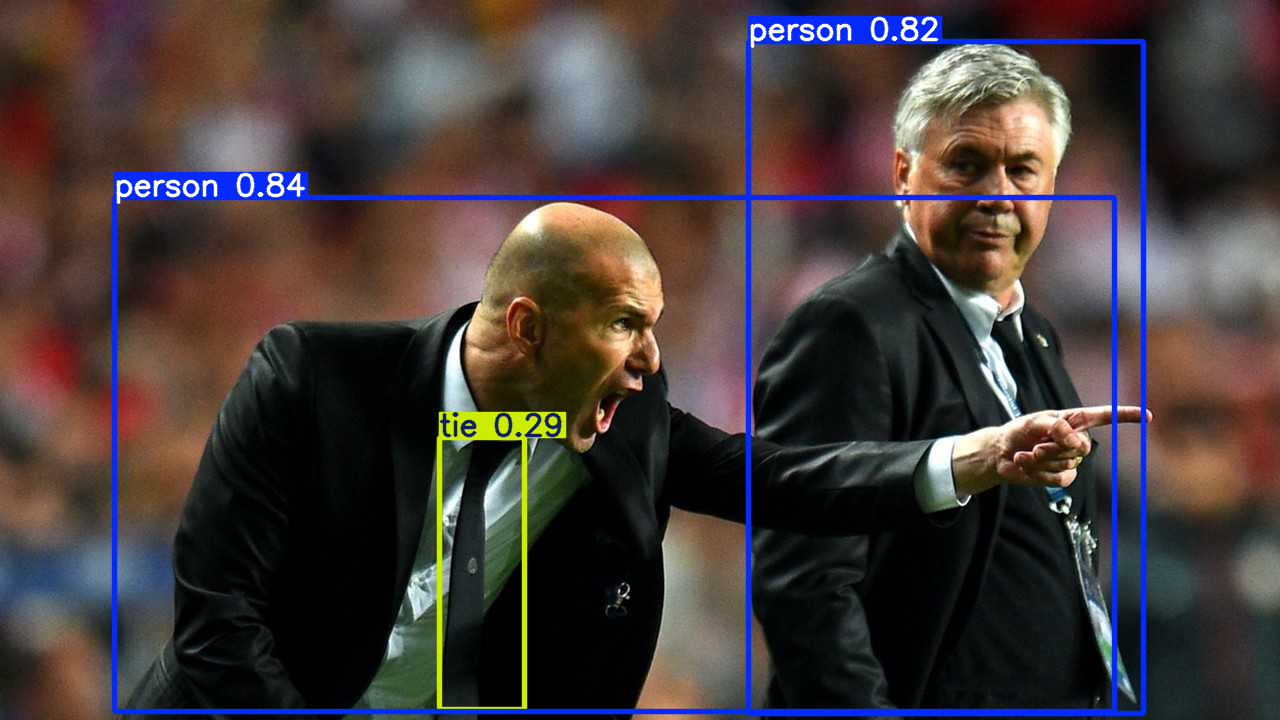

In [4]:
!pip install -q ultralytics
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

# 1. En güncel YOLO modelini (YOLOv8n) çağırıyoruz
model = YOLO("yolov8n.pt")

# 2. Kuşbakışı / İHA açısına benzer kalabalık bir sokak/trafik görseli üzerinde test edelim
url = "https://ultralytics.com/images/zidane.jpg" # Şimdilik test için standart görsel
results = model(url)

# 3. Tespit edilen nesnelerin görselini ekrana bastıralım
res_plotted = results[0].plot()
cv2_imshow(res_plotted)

--2026-10-16 11:20:46--  https://ultralytics.com/images/bus.jpg
Resolving ultralytics.com (ultralytics.com)... 216.150.1.1
Connecting to ultralytics.com (ultralytics.com)|216.150.1.1|:443... connected.
HTTP request sent, awaiting response... 308 Permanent Redirect
Location: https://www.ultralytics.com/images/bus.jpg [following]
--2026-10-16 11:20:46--  https://www.ultralytics.com/images/bus.jpg
Resolving www.ultralytics.com (www.ultralytics.com)... 216.150.1.129, 216.150.16.129
Connecting to www.ultralytics.com (www.ultralytics.com)|216.150.1.129|:443... connected.
HTTP request sent, awaiting response... 308 Permanent Redirect
Location: https://github.com/ultralytics/assets/releases/download/v0.0.0/bus.jpg [following]
--2026-10-16 11:20:46--  https://github.com/ultralytics/assets/releases/download/v0.0.0/bus.jpg
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Lo

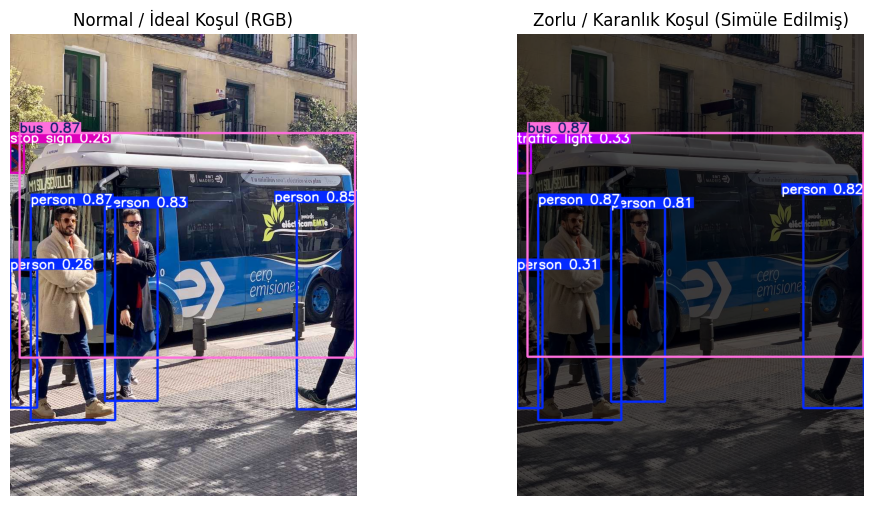

In [5]:
# 1. Gerekli kütüphaneleri yüklüyoruz ve içe aktarıyoruz
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 2. YOLO modelimizi yüklüyoruz
model = YOLO("yolov8n.pt")

# 3. Test için örnek bir görsel indirelim
!wget -O test_image.jpg "https://ultralytics.com/images/bus.jpg"

# 4. Görüntüyü okuyalım
img = cv2.imread("test_image.jpg")

# 5. Görseli simüle edilmiş "zorlu koşullara" (örneğin sis veya düşük ışık / karanlık) uyarlayalım
# Düşük ışık simülasyonu için piksellerin parlaklığını azaltalım (karanlık gece koşulu)
dark_img = cv2.convertScaleAbs(img, alpha=0.3, beta=0) # Parlaklık çok düşük

# Normal görsel ve karanlık görsel üzerinde nesne tespiti yapalım
results_normal = model(img)
results_dark = model(dark_img)

# Sonuçları yan yana görselleştirelim
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(cv2.cvtColor(results_normal[0].plot(), cv2.COLOR_BGR2RGB))
axes[0].set_title("Normal / İdeal Koşul (RGB)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(results_dark[0].plot(), cv2.COLOR_BGR2RGB))
axes[1].set_title("Zorlu / Karanlık Koşul (Simüle Edilmiş)")
axes[1].axis("off")

plt.show()
